Efeito Verdadeiro Injetado: 5
----------------------------------------------------------------------
A/B Ingênuo:       Estima 6.14 | Erro Padrão (SE): 0.423 | VIESADO
Cluster Puro:     Estima 4.88 | Erro Padrão (SE): 0.386 | IC 95%: [4.12, 5.64]
Cluster + CUPED:  Estima 4.93 | Erro Padrão (SE): 0.208 | IC 95%: [4.52, 5.34]
----------------------------------------------------------------------
Redução da Variância dos Dados de Usuários: 71.0%
Redução da Variância do Estimador (SE^2):     71.1%
Aumento Real de Precisão (1 / SE^2):         245.5%
Economia de tamanho amostral equivalente:    71.1%

[Sucesso] Gráfico salvo como 'cuped_variance_reduction.png' na pasta atual!


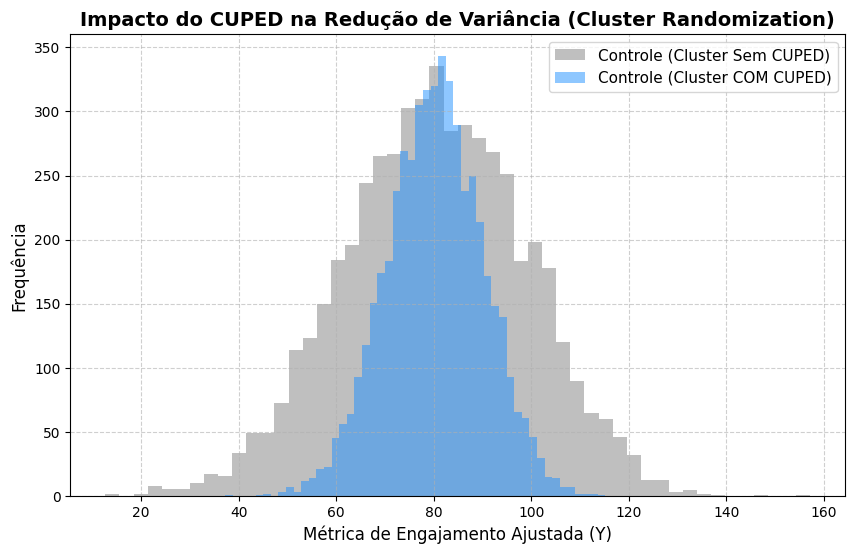

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Configuração Inicial e Parâmetros
np.random.seed(42)

N_USERS = 10000
N_CLUSTERS = 300
TRUE_EFFECT = 5
SPILLOVER_EFFECT = 3  # Contaminação se amigos estão no tratamento

# Simulação da base com rede / clusters
df = pd.DataFrame({
    'user_id': range(N_USERS),
    'cluster_id': np.random.choice(range(N_CLUSTERS), N_USERS),
    'X_pre': np.random.normal(100, 20, N_USERS)  # Covariável: tempo no app 14d antes
})

# 2. Desenho 1: A/B Ingênuo (Violação de SUTVA)
df['treatment_naive'] = np.random.binomial(1, 0.5, N_USERS)

# Calcula a porcentagem do cluster em tratamento para simular o spillover
cluster_treat_pct = df.groupby('cluster_id')['treatment_naive'].mean().to_dict()
df['cluster_treat_pct'] = df['cluster_id'].map(cluster_treat_pct)

# Y com spillover (afetado pelos outros membros do cluster)
df['Y_naive'] = (
    df['X_pre'] * 0.8 +
    np.random.normal(0, 10, N_USERS) +
    df['treatment_naive'] * TRUE_EFFECT +
    df['cluster_treat_pct'] * SPILLOVER_EFFECT  # <- Violação da SUTVA
)

# 3. Desenho 2: Cluster Randomization (Corrige SUTVA)
cluster_treatment = {c: np.random.binomial(1, 0.5) for c in range(N_CLUSTERS)}
df['treatment_cluster'] = df['cluster_id'].map(cluster_treatment)

# Sem spillover: o tratamento é atribuído a nível de cluster inteiro
df['Y_cluster'] = (
    df['X_pre'] * 0.8 +
    np.random.normal(0, 10, N_USERS) +
    df['treatment_cluster'] * TRUE_EFFECT
)

# 4. CUPED: A Correção de Variância
# O theta deve ser calculado apenas no grupo de controle para evitar viés
control_mask = df['treatment_cluster'] == 0
cov_yx = np.cov(df.loc[control_mask, 'Y_cluster'], df.loc[control_mask, 'X_pre'])[0, 1]
var_x = df['X_pre'].var()
theta = cov_yx / var_x

X_mean = df['X_pre'].mean()
df['Y_cuped'] = df['Y_cluster'] - theta * (df['X_pre'] - X_mean)

# 5. Avaliação dos Resultados e Erro Padrão do Experimento (levando em conta clusters)
def evaluate_experiment(y_col, treat_col):
    # Médias dos grupos
    mean_treat = df[df[treat_col] == 1][y_col].mean()
    mean_control = df[df[treat_col] == 0][y_col].mean()
    point_estimate = mean_treat - mean_control

    # Como a randomização foi feita por cluster, o cálculo correto do Erro Padrão (SE)
    # deve ser feito agregando as métricas a nível de cluster para não subestimar o erro.
    cluster_df = df.groupby('cluster_id').agg(
        y_mean=(y_col, 'mean'),
        treat=(treat_col, 'first'),
        weight=('user_id', 'count')
    )

    # Erro padrão robusto aproximado para a diferença de médias por cluster
    treat_clusters = cluster_df[cluster_df['treat'] == 1]['y_mean']
    control_clusters = cluster_df[cluster_df['treat'] == 0]['y_mean']

    n_t = len(treat_clusters)
    n_c = len(control_clusters)

    se = np.sqrt(treat_clusters.var() / n_t + control_clusters.var() / n_c)
    return point_estimate, se, df[y_col].var()

eff_naive, se_naive, var_naive = evaluate_experiment('Y_naive', 'treatment_naive')
eff_cluster, se_cluster, var_cluster = evaluate_experiment('Y_cluster', 'treatment_cluster')
eff_cuped, se_cuped, var_cuped = evaluate_experiment('Y_cuped', 'treatment_cluster')

# Precisão é proporcional ao inverso da variância do estimador (1 / SE^2)
# A redução de tamanho amostral necessária para obter o mesmo SE é proporcional à razão das variâncias.
sample_size_reduction = (1 - (se_cuped**2 / se_cluster**2)) * 100

print("=" * 70)
print(f"Efeito Verdadeiro Injetado: {TRUE_EFFECT}")
print("-" * 70)
print(f"A/B Ingênuo:       Estima {eff_naive:.2f} | Erro Padrão (SE): {se_naive:.3f} | VIESADO")
print(f"Cluster Puro:     Estima {eff_cluster:.2f} | Erro Padrão (SE): {se_cluster:.3f} | IC 95%: [{eff_cluster - 1.96*se_cluster:.2f}, {eff_cluster + 1.96*se_cluster:.2f}]")
print(f"Cluster + CUPED:  Estima {eff_cuped:.2f} | Erro Padrão (SE): {se_cuped:.3f} | IC 95%: [{eff_cuped - 1.96*se_cuped:.2f}, {eff_cuped + 1.96*se_cuped:.2f}]")
print("-" * 70)
print(f"Redução da Variância dos Dados de Usuários: {((1 - var_cuped / var_cluster)*100):.1f}%")
print(f"Redução da Variância do Estimador (SE^2):     {((1 - (se_cuped**2 / se_cluster**2))*100):.1f}%")
print(f"Aumento Real de Precisão (1 / SE^2):         {((se_cluster**2 / se_cuped**2) - 1)*100:.1f}%")
print(f"Economia de tamanho amostral equivalente:    {sample_size_reduction:.1f}%")
print("=" * 70)

# 6. Geração do Gráfico para o GitHub
plt.figure(figsize=(10, 6))

plt.hist(df[df['treatment_cluster'] == 0]['Y_cluster'], bins=50, alpha=0.5, label='Controle (Cluster Sem CUPED)', color='gray')
plt.hist(df[df['treatment_cluster'] == 0]['Y_cuped'], bins=50, alpha=0.5, label='Controle (Cluster COM CUPED)', color='dodgerblue')

plt.title('Impacto do CUPED na Redução de Variância (Cluster Randomization)', fontsize=14, fontweight='bold')
plt.xlabel('Métrica de Engajamento Ajustada (Y)', fontsize=12)
plt.ylabel('Frequência', fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)

# Salva a imagem para o repositório
plt.savefig('cuped_variance_reduction.png', dpi=300, bbox_inches='tight')
print("\n[Sucesso] Gráfico salvo como 'cuped_variance_reduction.png' na pasta atual!")

plt.show()